# sub-PAT16: isotropic versus tract-directed Fisher–KPP growth

This pilot uses **real pre-operative T1 anatomy, dMRI tensors and resting-state fMRI** from the BTC study and the related [brain digital-twin project](https://github.com/arvidl/glioma-brain-digital-twin-public). It compares **conditional simulated growth**, using assumed migration and proliferation rates. It does not estimate this patient's growth rate or forecast clinical outcomes.

**Run All** with the repository's Python environment. Set `PAT16_SOURCE` to the processed digital-twin project root if it is not found locally. Input requirements, coordinate conventions and reproducibility instructions are in [examples/pat16_pilot.md](examples/pat16_pilot.md). Missing inputs cause a clear error; imaging is never replaced with synthetic data. Pre/post-operative scans span surgery, so that pair is not an untreated-growth validation experiment.

The notebook provides: input and registration QA; a trace-matched isotropic/anisotropic comparison; 32 paired prior-sensitivity scenarios; synchronized time/slice controls; measured fMRI connectivity overlays; and regional simulated overlap. T1-Gd, T2 and FLAIR are not present in this pilot. The oxygen–necrosis extension remains available in the original explorer; this experiment isolates Fisher–KPP transport geometry.


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, json, time
ROOT = Path.cwd()
if not (ROOT / 'src/brainweb_kpp').is_dir():
    raise RuntimeError('Start Jupyter from the brainweb_fisher_kpp repository root.')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/brainweb-mpl')
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from brainweb_kpp.pat16 import (find_source, load_pilot, functional_network,
                               initial_density, sha256)
from brainweb_kpp.anisotropic import migration_tensor, transport_matrix, simulate
from brainweb_kpp.pat16_experiment import (run_ensemble, summarize, save_results,
    comparison_figure, uncertainty_figure, grid_field, slice_image)
OUTPUT = ROOT / 'outputs/pat16_pilot'
OUTPUT.mkdir(parents=True, exist_ok=True)
SOURCE = find_source()  # Or find_source('/absolute/path/to/processed/project')
SPACING_MM = 3.
N_SCENARIOS = 32
RANDOM_SEED = 16026
TIMES_DAYS = np.arange(0., 91., 15.)
print('Real pre-op MRI derivatives found. Growth parameters below are assumed, not fitted.')


Real pre-op MRI derivatives found. Growth parameters below are assumed, not fitted.


## 1. MRI anatomy, tract directions and coordinate checks

All scalar images are resampled using their full NIfTI affines onto one 3 mm, axis-aligned **RAS** grid. Tissue classes come from the *named* CSF/GM/WM probability maps, avoiding pipeline-dependent integer-label conventions. CSF and extracerebral voxels have zero transport and growth. Voxels inside the lesion but classified as CSF by the healthy-tissue segmenter are included with **assumed GM-like transport**, with their number recorded.

The MRtrix diffusion tensor stores scanner-RAS components `(xx, yy, zz, xy, xz, yz)`. The saved rigid registration uses the **target-to-source pullback** convention. We resample tensor components, rotate them with the inverse rigid rotation, then diagonalize; we do not interpolate signed eigenvectors. Tensor-derived FA must correlate with the independently saved T1-space FA map at **r > 0.85**. This checks transformation consistency, not the biological correctness of the original dMRI processing. Eigenvector signs cancel in $vv^T$.

White matter with positive tensor eigenvalues and FA > 0.2 receives directional transport; other voxels remain isotropic. A single DTI direction cannot resolve crossing fibers. Tumor masks are study derivatives, not quantitative cell-density measurements. Their thresholds and initial density are varied below.


In [2]:
pilot = load_pilot(SOURCE, spacing=SPACING_MM)
network = functional_network(SOURCE)
print(json.dumps({k: pilot.provenance[k] for k in (
    'grid_shape', 'active_voxels', 'lesion_tissue_override_voxels',
    'fa_alignment_correlation', 'dti_b_shells_s_per_mm2')}, indent=2))
print('Directional WM voxels:', int(pilot.anisotropic.sum()))
print('BOLD frames retained:', network['qc']['retained_frames'], '/', network['qc']['total_frames'])
print('Functional ROIs:', len(network['ids']), '; residual model degrees of freedom:', network['qc']['residual_dof'])
center_ijk = np.rint(np.argwhere(pilot.lesion > .5).mean(axis=0)).astype(int)
center_ras = pilot.affine[:3, :3] @ center_ijk + pilot.affine[:3, 3]
print('Illustrated lesion center, RAS mm:', center_ras)


{
  "grid_shape": [
    51,
    62,
    50
  ],
  "active_voxels": 44667,
  "lesion_tissue_override_voxels": 603,
  "fa_alignment_correlation": 0.996777494672504,
  "dti_b_shells_s_per_mm2": [
    0,
    500,
    1000,
    3000
  ]
}
Directional WM voxels: 18202
BOLD frames retained: 157 / 180
Functional ROIs: 82 ; residual model degrees of freedom: 121
Illustrated lesion center, RAS mm: [ 30.  36. -12.]


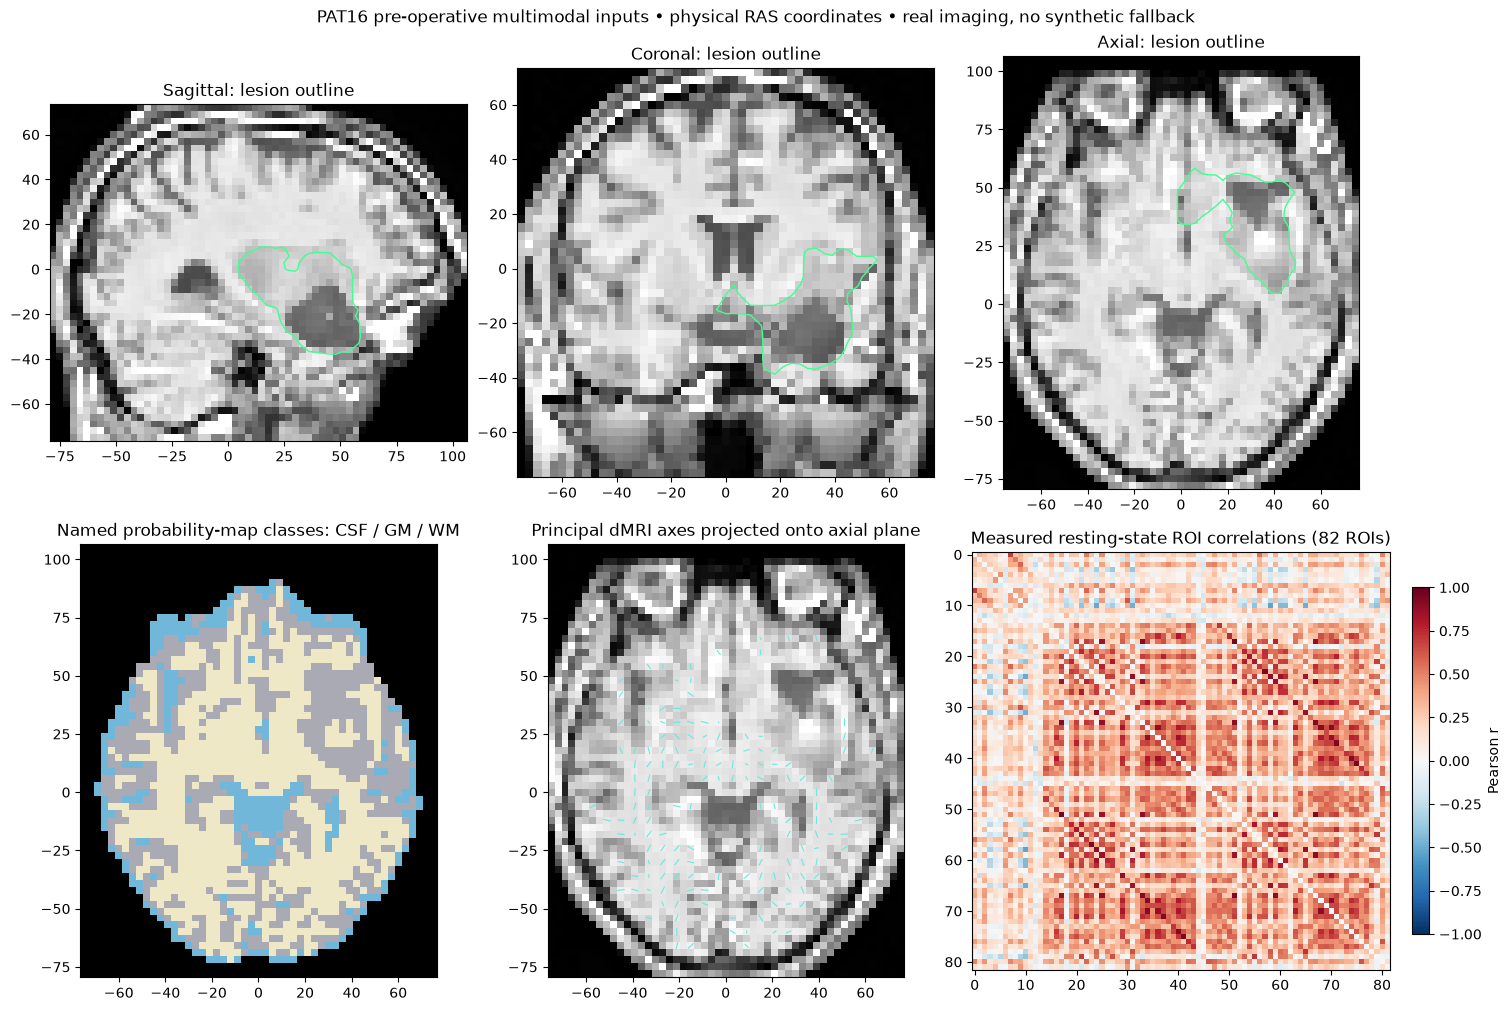

In [3]:
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout='constrained')
for axis, ax in enumerate(axes[0]):
    image, extent, _ = slice_image(pilot, pilot.t1, axis, center_ijk[axis])
    lesion, _, _ = slice_image(pilot, pilot.lesion, axis, center_ijk[axis])
    ax.imshow(image, origin='lower', extent=extent, cmap='gray', vmin=0, vmax=1)
    ax.contour(lesion, [.5], colors=['#42ff92'], linewidths=1, origin='lower', extent=extent)
    ax.set_title(['Sagittal: lesion outline', 'Coronal: lesion outline', 'Axial: lesion outline'][axis])
image, extent, _ = slice_image(pilot, pilot.tissue, 2, center_ijk[2])
axes[1, 0].imshow(image, origin='lower', extent=extent, cmap=ListedColormap(['black','#70b7d9','#aaaab5','#eee8c6']), vmin=0, vmax=3)
axes[1, 0].set_title('Named probability-map classes: CSF / GM / WM')
image, extent, _ = slice_image(pilot, pilot.t1, 2, center_ijk[2])
axes[1, 1].imshow(image, origin='lower', extent=extent, cmap='gray', vmin=0, vmax=1)
z = center_ijk[2]
xx, yy = np.meshgrid(np.arange(pilot.mask.shape[0]), np.arange(pilot.mask.shape[1]), indexing='ij')
use = pilot.anisotropic[:, :, z] & (xx % 2 == 0) & (yy % 2 == 0)
v = pilot.directions[:, :, z][use]
x = pilot.affine[0, 3] + xx[use]*SPACING_MM
y = pilot.affine[1, 3] + yy[use]*SPACING_MM
axes[1, 1].quiver(x, y, v[:, 0], v[:, 1], color='#67e8e0', angles='xy', scale_units='xy', scale=.3,
                  headwidth=0, headlength=0, headaxislength=0, pivot='middle', width=.003)
axes[1, 1].set_title('Principal dMRI axes projected onto axial plane')
artist = axes[1, 2].imshow(network['fc'], cmap='RdBu_r', vmin=-1, vmax=1)
axes[1, 2].set_title('Measured resting-state ROI correlations (82 ROIs)')
fig.colorbar(artist, ax=axes[1, 2], label='Pearson r', shrink=.8)
fig.suptitle('PAT16 pre-operative multimodal inputs • physical RAS coordinates • real imaging, no synthetic fallback')
fig.savefig(OUTPUT / 'input_qa.png', dpi=160)
plt.show()


## 2. Matched Fisher–KPP models and numerical scheme

Normalized viable density $u=c/K$ obeys
$$
\partial_t u=\nabla\cdot(D(x)\nabla u)+\rho u(1-u),\qquad
\boldsymbol{n}\cdot D\nabla u=0.
$$
The isotropic reference uses $D_{\rm iso}(x)=d(x)I$, with separate assumed WM and GM rates. The directional model uses
$$
D_{\rm ani}=d_\perp I+(d_\parallel-d_\perp)vv^T,
\quad d_\perp=\frac{3d}{r+2},\quad d_\parallel=r d_\perp.
$$
Thus $\operatorname{tr}D_{\rm ani}/3=d$: the models have the **same local mean diffusivity**, proliferation, initial state and tissue domain. Only eligible WM becomes anisotropic. dMRI supplies a direction prior; measured water diffusivities in mm²/s are **not converted into tumor migration rates in mm²/day**.

For a symmetric diagonally dominant tensor, use the exact decomposition
$$
D=\sum_i\left(D_{ii}-\sum_{j\ne i}|D_{ij}|\right)e_ie_i^T
+\sum_{i<j}|D_{ij}|(e_i+\operatorname{sgn}(D_{ij})e_j)
(e_i+\operatorname{sgn}(D_{ij})e_j)^T.
$$
It gives nonnegative conductances along axes and face diagonals, retaining the **mixed derivatives**. Harmonic conductances define equal and opposite fluxes. Diagonal links require both intermediate corner voxels to belong to tissue. This approximates a no-flux boundary on a stair-step domain; it does not model microscopic barriers or vessel routes. The explicit diffusion step satisfies $\Delta t\max_i\sum_{j\ne i}w_{ij}\le0.9$; exact logistic reaction follows. No density clipping is used.

The pilot restricts $1\le r\le3.5$ to guarantee diagonal dominance for any orientation. This is a **numerical restriction**, not a biological bound. Larger anisotropy requires a wider monotone stencil or a different solver. It reduces exactly to the existing harmonic face-flux Fisher–KPP scheme when $r=1$.


## 3. Assumed uncertainty and paired scenarios

The following distributions are **illustrative priors/sensitivity assumptions**. They have not been estimated from PAT16 or validated against untreated serial MRI.

| Quantity | Distribution | Interpretation |
|---|---|---|
| $D_{WM}$ | log-normal, median 0.5 mm²/day, log-SD 0.25 | Migration magnitude |
| $D_{GM}$ | log-normal, median 0.1 mm²/day, log-SD 0.25 | Independently varied GM magnitude |
| $\rho$ | log-normal, median 0.04 day⁻¹, log-SD 0.20 | Shared proliferation |
| $r=d_\parallel/d_\perp$ | Uniform(1.5, 3.5) | Directional strength |
| Initial amplitude $u_0$ | Uniform(0.4, 0.8) | Unknown cellularity in the lesion |
| Lesion-probability threshold | Uniform(0.4, 0.6) | Segmentation sensitivity |
| Direction perturbation | random global axis; angle Normal(0, 3°) | Assumed direction sensitivity, not a registration posterior |

A Latin-hypercube design supplies 32 paired draws. Each pair shares parameters and initialization; only transport anisotropy changes. The thresholded lesion is smoothed with sigma 0.7 voxels and multiplied by its assumed amplitude. Time zero means the pre-operative initialization, **not tumor onset**. The 90 days are hypothetical untreated time, with no resection or treatment event.

Bands are empirical **5th–95th prior-sensitivity percentiles**, not confidence intervals, posterior credible intervals or evidence of uncertainty calibration. Pointwise median maps need not correspond to one simulated realization. The finite ensemble omits substantial model and imaging uncertainty, including full tensor-fit uncertainty, alternative tissue masks, crossing fibers, swelling and treatment effects.


In [4]:
started = time.perf_counter()
def progress(done, total):
    if done % 8 == 0 or done == total:
        print(f'Completed {done}/{total} paired scenarios', flush=True)
result = run_ensemble(pilot, n=N_SCENARIOS, seed=RANDOM_SEED, times=TIMES_DAYS, progress=progress)
summary = summarize(pilot, network, result)
report = save_results(pilot, network, result, summary, OUTPUT)
print(f'Completed in {time.perf_counter()-started:.1f} seconds.')
for model, name in enumerate(['Isotropic', 'Anisotropic']):
    q = np.quantile(summary['burden_ml'][:, model, -1], [.05, .5, .95])
    print(f'{name}, day 90 integral u dV: median {q[1]:.2f} mL; prior 5th–95th [{q[0]:.2f}, {q[2]:.2f}]')
print('Paired day-90 burden difference, anisotropic minus isotropic (q05, q50, q95), mL:')
print(report['paired_final_burden_difference_ml_q05_q50_q95'])
assert np.array_equal(result['states'][:, 0, 0], result['states'][:, 1, 0])


Completed 8/32 paired scenarios
Completed 16/32 paired scenarios
Completed 24/32 paired scenarios
Completed 32/32 paired scenarios
Completed in 6.7 seconds.
Isotropic, day 90 integral u dV: median 110.42 mL; prior 5th–95th [86.30, 137.58]
Anisotropic, day 90 integral u dV: median 106.74 mL; prior 5th–95th [85.28, 133.17]
Paired day-90 burden difference, anisotropic minus isotropic (q05, q50, q95), mL:
[-6.803939669831078, -2.9816453331003245, -0.8496133378309048]


## 4. Synchronized comparison and fMRI overlays

All four panels share time, plane and slice controls. Color scales are fixed across time. The first two panels show the selected prior quantile; the difference is the median of **paired** differences. The fourth panel is the fraction of anisotropic scenarios exceeding $u=0.16$, an **illustrative simulation threshold**, not an MRI detection threshold or clinical tumor probability.

Cyan and purple edges are positive and negative **measured, static resting-state correlations** between atlas ROI centers in a ±12 mm slab, with $|r|\ge0.35$ and at most 35 strongest edges. They are projected through the slab, not tract paths. Toggle them off to inspect density. They never evolve with the simulated tumor. The green contour is the initial lesion.

fMRI is recomputed from the real fMRIPrep T1-space BOLD: nearest-neighbor atlas resampling by full affine; censor FD > 0.5 mm and nonsteady frames; jointly regress 24 motion terms, five aCompCor components, supplied high-pass cosines, linear trend and intercept on retained frames. No extra low-pass filter or global-signal regression is used. These are exploratory regional correlations, not named canonical-network assignments, causal connections, surgical eloquence maps or statistical significance tests. Motion, parcellation errors and tumor-associated neurovascular uncoupling can alter them.


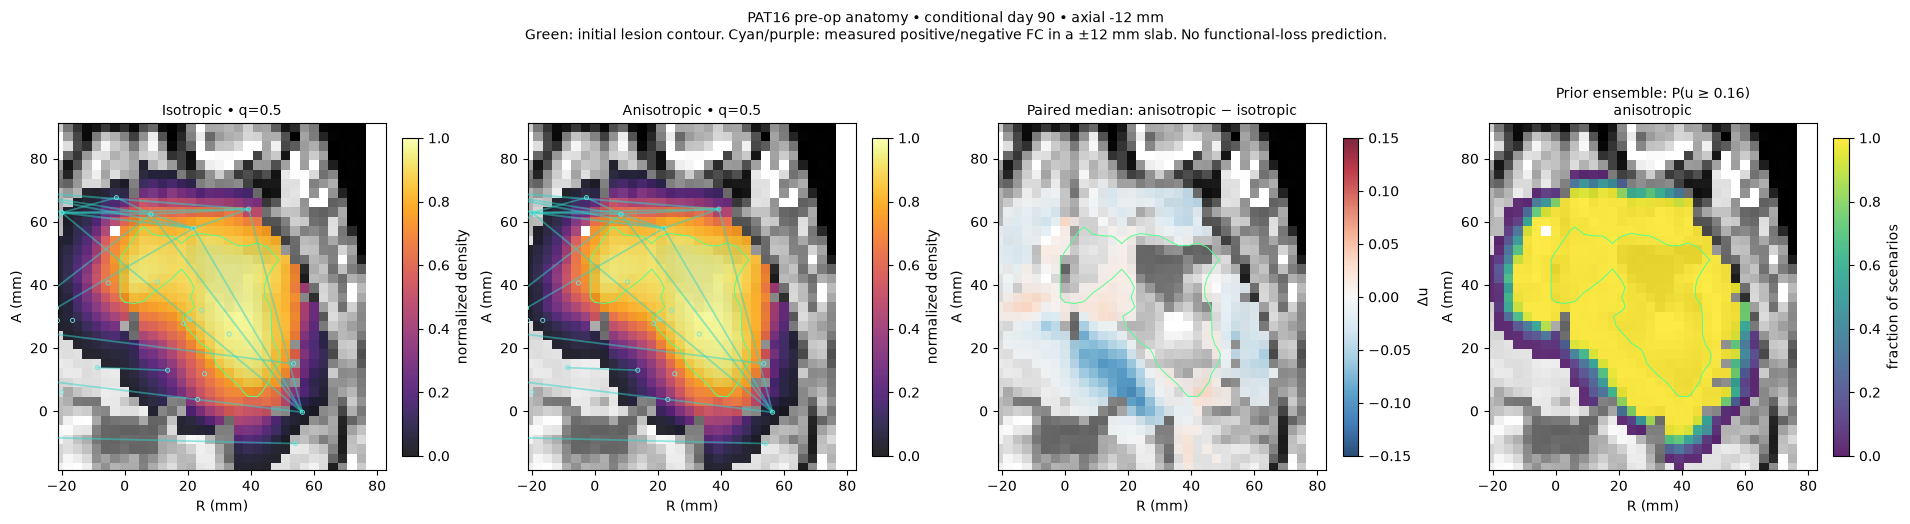

In [5]:
fig = comparison_figure(pilot, network, result, frame=-1, axis=2, index=center_ijk[2], overlay=True)
fig.savefig(OUTPUT / 'day90_comparison.png', dpi=170)
plt.show()


In [6]:
import ipywidgets as widgets
from io import BytesIO
time_control = widgets.SelectionSlider(options=[(f'Day {t:g}', i) for i, t in enumerate(result['times'])],
                                       value=len(result['times'])-1, description='Time', continuous_update=False,
                                       layout=widgets.Layout(width='270px'))
plane_control = widgets.Dropdown(options=[('Sagittal',0),('Coronal',1),('Axial',2)], value=2, description='Plane',
                                 layout=widgets.Layout(width='240px'))
slice_control = widgets.IntSlider(min=0, max=pilot.mask.shape[2]-1, value=int(center_ijk[2]),
                                  description='Slice', continuous_update=False, layout=widgets.Layout(width='270px'))
quantile_control = widgets.Dropdown(options=[('Median',.5),('5th percentile',.05),('95th percentile',.95)], value=.5,
                                    description='Density', layout=widgets.Layout(width='240px'))
overlay_control = widgets.Checkbox(value=True, description='Measured fMRI overlay', layout=widgets.Layout(width='240px'))
zoom_control = widgets.Checkbox(value=True, description='Lesion zoom', layout=widgets.Layout(width='200px'))
columns_control = widgets.Dropdown(options=[('Two columns',2),('Four columns',4)], value=2,
                                   description='Panels', layout=widgets.Layout(width='240px'))
viewer = widgets.Image(format='png', layout=widgets.Layout(width='100%'))
def redraw(*_):
    fig = comparison_figure(pilot, network, result, frame=time_control.value,
        axis=plane_control.value, index=slice_control.value, quantile=quantile_control.value,
        overlay=overlay_control.value, zoom=zoom_control.value, columns=columns_control.value)
    image = BytesIO()
    fig.savefig(image, format='png', dpi=120)
    plt.close(fig)
    viewer.value = image.getvalue()
def change_plane(change):
    axis = change['new']
    slice_control.max = pilot.mask.shape[axis]-1
    slice_control.value = int(center_ijk[axis])
    redraw()
plane_control.observe(change_plane, names='value')
for control in (time_control, slice_control, quantile_control, overlay_control, zoom_control, columns_control):
    control.observe(redraw, names='value')
display(widgets.VBox([widgets.Box([time_control, plane_control, slice_control, quantile_control,
                                  columns_control, overlay_control, zoom_control],
                                  layout=widgets.Layout(display='flex', flex_flow='row wrap', width='100%')), viewer]))
redraw()


## 5. Uncertainty and regional simulated overlap

The integral $\int u\,dV$ is a normalized-density burden expressed as an equivalent volume; it is **not an observed tumor volume or an absolute cell count**. The second metric counts voxels above an assumed $u=0.16$. Regional exposure is mean simulated $u$ within the atlas ROI's modeled tissue voxels; it is a geometrical overlap summary, **not predicted functional impairment**. ROIs below are ranked by the mean of both models' median exposure at day 90. Functional correlations provide context only; no neuron–glioma feedback is inferred from FC.


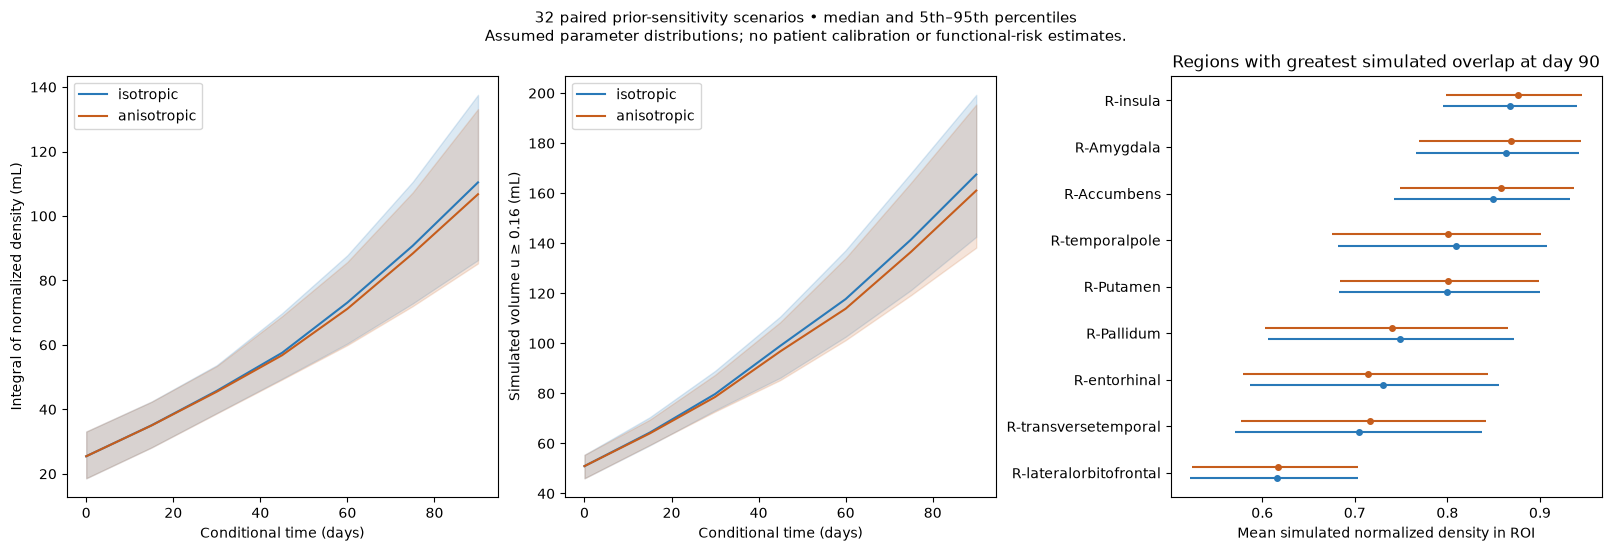

Regional exposure table: outputs/pat16_pilot/regional_exposure.csv


In [7]:
fig = uncertainty_figure(result, summary, network)
fig.savefig(OUTPUT / 'uncertainty_and_regions.png', dpi=170)
plt.show()
print('Regional exposure table:', (OUTPUT / 'regional_exposure.csv').relative_to(ROOT))


## 6. Numerical verification and validation plan

Automated tests check tensor trace, sign invariance, signed/permuted MIF layouts, rigid tensor reorientation, affine-aware resampling, non-axis-aligned mixed derivatives, conservation, density bounds, blocked corners and the isotropic limit. A representative scenario is repeated below with half the maximum time step. This is **time-step sensitivity**, not spatial convergence or validation of patient growth.

Next validation needs: inspect dMRI/fMRI preprocessing reports and registration landmarks; validate lesion and tissue masks; compare tensor/FOD direction models and finer grids; characterize fMRI nuisance-model sensitivity; acquire untreated serial tumor-sensitive MRI with calibrated observation models and treatment dates; estimate identifiable rates with uncertainty; withhold later scans and external patients; evaluate network and cognitive hypotheses against independent functional outcomes. The postoperative scan can support a separate resection/mechanics experiment once intervention effects are modeled. BOLD attenuation can reflect neurovascular uncoupling and does not prove loss of function.


In [8]:
diffusion = np.where(pilot.tissue == 3, .5, .1) * pilot.mask
tensor = migration_tensor(diffusion, pilot.directions, ratio=2.5, eligible=pilot.anisotropic)
matrix, active = transport_matrix(tensor, pilot.mask, SPACING_MM)
initial = initial_density(pilot).ravel()[active]
coarse, dt_coarse = simulate(matrix, initial, [0.,90.], rho=.04, dt=.5)
fine, dt_fine = simulate(matrix, initial, [0.,90.], rho=.04, dt=.25)
relative_l1 = float(np.abs(coarse[-1]-fine[-1]).sum()/np.abs(fine[-1]).sum())
pure_diffusion, _ = simulate(matrix, initial, [0.,5.], rho=0, dt=.5)
relative_mass_error = float(abs(pure_diffusion[1].sum(dtype=float)-pure_diffusion[0].sum(dtype=float)) / pure_diffusion[0].sum(dtype=float))
verification = {'representative_day90_dt_half_relative_L1': relative_l1,
                'dt_days': [dt_coarse, dt_fine], 'pure_diffusion_5day_relative_mass_error': relative_mass_error,
                'ensemble_density_min': report['min_density'], 'ensemble_density_max': report['max_density'],
                'shared_initial_states': bool(np.array_equal(result['states'][:,0,0], result['states'][:,1,0]))}
print(json.dumps(verification, indent=2))
assert relative_l1 < .02, 'Time-step sensitivity requires investigation'
assert relative_mass_error < 1e-6, 'Conservation check failed'
(OUTPUT / 'verification.json').write_text(json.dumps(verification, indent=2)+'\n')


{
  "representative_day90_dt_half_relative_L1": 0.0008056312217377126,
  "dt_days": [
    0.5,
    0.25
  ],
  "pure_diffusion_5day_relative_mass_error": 5.685595440537716e-10,
  "ensemble_density_min": 0.0,
  "ensemble_density_max": 0.9973234534263611,
  "shared_initial_states": true
}


288

## 7. Saved outputs and sources

`outputs/pat16_pilot/` contains input QA, synchronized day-90 comparison, uncertainty and regional-overlap figures, JSON summaries, a regional CSV, numerical checks and input/code checksums. The large ensemble cache is ignored by Git. Patient input volumes are read in place; they are not copied into the repository. Figures are simulation outputs on actual MRI anatomy. No rates, cell-density maps or cognitive outcomes have been recovered from the patient scans.

Primary sources and technical conventions:

1. Aerts et al. (2022), [BTC multimodal pre/post-operative dataset](https://doi.org/10.1038/s41597-022-01806-4); [OpenNeuro ds001226](https://openneuro.org/datasets/ds001226).
2. [Glioma brain digital-twin prototype](https://github.com/arvidl/glioma-brain-digital-twin-public): source preprocessing and workshop derivatives. Input hashes identify the actual local derivative files used here.
3. MRtrix3: [file layouts](https://userdocs.mrtrix.org/en/latest/getting_started/image_data.html), [gradient conventions](https://userdocs.mrtrix.org/en/latest/concepts/dw_scheme.html), [reverse transform convention](https://userdocs.mrtrix.org/en/latest/reference/commands/mrtransform.html), [tensor component order](https://github.com/MRtrix3/mrtrix3/blob/3.0.8/cmd/tensor2metric.cpp).
4. [fMRIPrep outputs and confounds](https://fmriprep.org/en/latest/outputs.html); Tournier et al. (2019), [MRtrix3](https://doi.org/10.1016/j.neuroimage.2019.116137).
5. Sun et al. (2020), [tumor-associated neurovascular uncoupling](https://doi.org/10.1148/radiol.2019190089).

The supplied 2026 digital-twin code is a methods demonstrator. This notebook adds a conditional growth experiment, not clinical validation. Its DTI header records shells 0/500/1000/3000 s/mm²; the actual processed header, rather than a generic protocol description, is recorded in provenance.
